# Spline features for smooth non-linearity

Splines represent a relationship with several low-degree polynomial pieces joined at knots. They can model a smooth curve while avoiding the unstable behaviour of one very high-degree polynomial.

## Why use splines?

A house-price relationship may rise quickly at small living areas and then flatten. A straight line misses the curve; a high-degree polynomial can oscillate; a spline gives local flexibility. The number of knots controls flexibility and must be validated.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import SplineTransformer,StandardScaler
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
sns.set_theme(style='whitegrid',context='notebook')

candidates=[Path('feature-engineering/imputation/houseprice.csv'),Path('../imputation/houseprice.csv'),Path('houseprice.csv')]
path=next((p for p in candidates if p.exists()),None)
if path is None: raise FileNotFoundError('Place houseprice.csv in feature-engineering/imputation/.')
data=pd.read_csv(path,na_values=['NA'])
model_data=data[['GrLivArea','SalePrice']].dropna().copy()
X=model_data[['GrLivArea']]; y=model_data['SalePrice']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42)

## 1. Inspect the spline basis

The transformer creates several basis columns. The model learns a coefficient for each basis column, and their weighted sum forms a smooth curve.

Basis shape: (1168, 6)


,GrLivArea_sp_0,GrLivArea_sp_1,GrLivArea_sp_2,GrLivArea_sp_3,GrLivArea_sp_4,GrLivArea_sp_5
0,0.002980,0.322662,0.607229,0.067130,0.000000,0.0
1,0.000052,0.202722,0.662223,0.135004,0.000000,0.0
2,0.046162,0.566556,0.380249,0.007033,0.000000,0.0
3,0.000000,0.129514,0.660427,0.209972,0.000087,0.0
4,0.000000,0.155617,0.666161,0.178220,0.000002,0.0


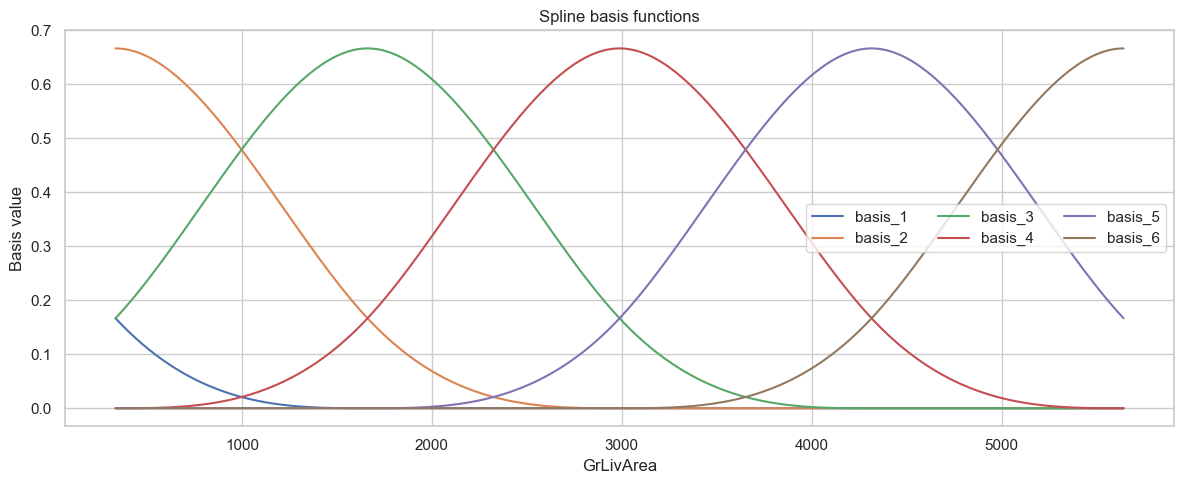

In [2]:
spline_basis=SplineTransformer(n_knots=5,degree=3,include_bias=False)
basis=spline_basis.fit_transform(X_train)
print('Basis shape:',basis.shape)
display(pd.DataFrame(basis,columns=spline_basis.get_feature_names_out(['GrLivArea'])).head())
grid=pd.DataFrame({'GrLivArea':np.linspace(X_train['GrLivArea'].min(),X_train['GrLivArea'].max(),300)})
grid_basis=spline_basis.transform(grid)
plt.figure(figsize=(12,5))
for index in range(grid_basis.shape[1]): plt.plot(grid['GrLivArea'],grid_basis[:,index],label=f'basis_{index+1}')
plt.title('Spline basis functions'); plt.xlabel('GrLivArea'); plt.ylabel('Basis value'); plt.legend(ncol=3); plt.tight_layout(); plt.show()

## 2. Compare a line with a spline model

The spline belongs inside the pipeline so its knots and scaling are learned from training data only. Ridge regularisation prevents unstable coefficients when basis columns overlap.

In [3]:
linear=Pipeline([('scale',StandardScaler()),('model',LinearRegression())])
spline=Pipeline([('spline',SplineTransformer(n_knots=5,degree=3,include_bias=False)),('scale',StandardScaler()),('model',Ridge(alpha=10.0))])
results=[]
for name,model in {'Linear baseline':linear,'Spline Ridge':spline}.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    results.append({'model':name,'MAE':mean_absolute_error(y_test,pred),'RMSE':np.sqrt(mean_squared_error(y_test,pred)),'R2':r2_score(y_test,pred)})
display(pd.DataFrame(results).set_index('model').round(2))

,MAE,RMSE,R2
model,,,
Linear baseline,38341.20,58471.76,0.55
Spline Ridge,38534.85,58122.68,0.56


## 3. Plot the fitted relationship

Sorting a one-feature test set makes the fitted curve easy to see. The dots are held-out observations, so the plot shows how the learned relationship behaves on unseen rows.

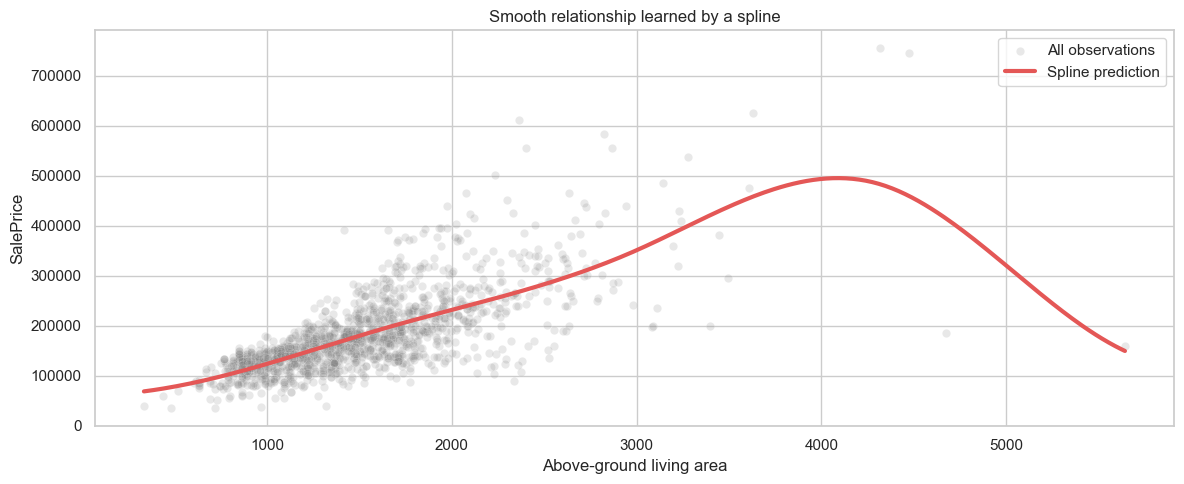

In [4]:
spline.fit(X_train,y_train)
grid_predictions=spline.predict(grid)
test_predictions=spline.predict(X_test)
plt.figure(figsize=(12,5))
sns.scatterplot(data=model_data,x='GrLivArea',y='SalePrice',alpha=.18,color='grey',label='All observations')
plt.plot(grid['GrLivArea'],grid_predictions,color='#E45756',linewidth=3,label='Spline prediction')
plt.xlabel('Above-ground living area'); plt.ylabel('SalePrice'); plt.title('Smooth relationship learned by a spline'); plt.legend(); plt.tight_layout(); plt.show()

## Choosing knots and degree

More knots create more flexibility and more risk of overfitting. A higher polynomial degree for each piece can also make the basis more flexible. Use cross-validation, residual checks, and business plausibility to select these values.

## Summary

Splines provide controlled smooth non-linearity. They are a useful alternative to a high-degree polynomial when the relationship changes gradually across the range of a feature.